<!-- Wersja do RPA_lab
<a href="https://colab.research.google.com/github/lorek/RPAI_lab/blob/main/Lista_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>
-->

<a href="https://colab.research.google.com/github/lorek/codex-probab/blob/main/notebooks/Lista_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

Paweł Lorek  
University of Wrocław

# Lista 3. Ruina gracza

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

## Ruina gracza — model
Dwaj gracze mają łącznie `M` zł. Pierwszy zaczyna z `N` zł, drugi z `M - N` zł.
W każdej rundzie rzucamy monetą, niezależnie od wcześniejszych rzutów:
- z prawdopodobieństwem `p` pierwszy gracz otrzymuje 1 zł od drugiego;
- z prawdopodobieństwem `1 - p` pierwszy gracz przekazuje 1 zł drugiemu.

Gra kończy się, gdy kapitał pierwszego gracza osiągnie **0 lub M**. Przy 0 pierwszy gracz przegrywa, przy M wygrywa. Po zakończeniu nie wykonujemy kolejnych rzutów.
Liczba rund jest losowa. W tej liście nie ustalamy limitu rund; dla skończonego M i 0 < p < 1 gra kończy się z prawdopodobieństwem 1.

Zaczynamy od `N = 8`, `M = 20` i uczciwej monety, czyli `p = 0.5`.
**Przed symulacją:** czy uczciwa moneta oznacza, że każdy gracz ma szansę 1/2 na wygranie całej gry?

## 1. Kapitał po kolejnych rundach
Najpierw prześledźmy krótki, z góry ustalony ciąg wyników. `+1` oznacza wygraną 1 zł, a `-1` stratę 1 zł.
`np.cumsum` liczy kolejne sumy: po pierwszej rundzie, po dwóch rundach itd. Do wykresu dodajemy kapitał początkowy w chwili 0.

Zmiany kapitału: [ 1 -1 -1  1  1]
Kapitał od chwili 0: [3 4 3 2 3 4]


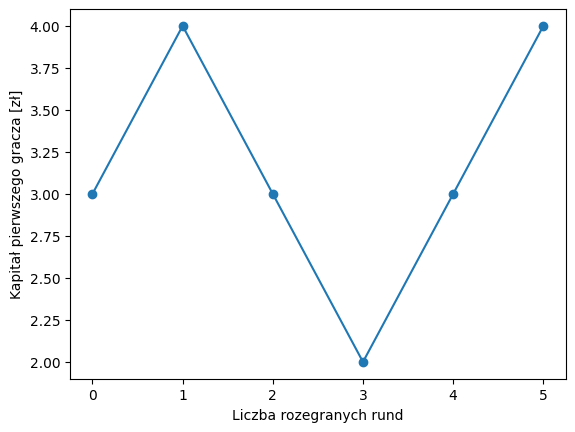

In [2]:
initial_capital = 3
steps = np.array([1, -1, -1, 1, 1])
capital_after_rounds = initial_capital + np.cumsum(steps)
example_path = np.concatenate(([initial_capital], capital_after_rounds))
print("Zmiany kapitału:", steps)
print("Kapitał od chwili 0:", example_path)
plt.plot(np.arange(example_path.size), example_path, "o-")
plt.xlabel("Liczba rozegranych rund")
plt.ylabel("Kapitał pierwszego gracza [zł]")
plt.xticks(np.arange(example_path.size))
plt.show()

**Zadanie 3.1.** Napisz funkcję `play_game(N, M, p, rng)`, która symuluje jedną całą grę i zwraca tablicę kapitałów, zaczynając od kapitału początkowego.
Przyjmujemy, że M i N są całkowite, 0 < N < M oraz 0 < p < 1.

1. Zacznij od `capital = N` oraz `path = [capital]`.
2. Użyj pętli `while 0 < capital < M`.
3. Wylosuj wynik jednej rundy: warunek `rng.random() < p` zachodzi z prawdopodobieństwem p. Zmień kapitał o +1 lub −1, a potem dopisz go przez `path.append(capital)`.
4. Po zakończeniu zwróć `np.array(path)`.

Uruchom funkcję dla N = 8, M = 20, p = 0.5. Narysuj kapitał w kolejnych rundach. Podaj zwycięzcę i liczbę rund.
 

In [ ]:
# TODO: Zaimplementuj jedną grę, narysuj jej przebieg i podaj wynik.

def play_game(N, M, p, rng):
    capital = N
    # TO DO
    return np.array(path)

## 2. Wiele niezależnych gier
**Zadanie 3.2.** Powtórz grę 5000 razy dla N = 8, M = 20 i p = 0.5. W każdej grze zaczynamy od tego samego kapitału N.

Zapisz do dwóch tablic:
- kapitał końcowy (`path[-1]`);
- liczbę rund (`len(path) - 1`), czyli długość każdej gry.

Oblicz częstość wygranej i ruiny pierwszego gracza oraz średni kapitał końcowy. Czy średni kapitał jest bliski początkowym 8 zł? Czy szansa wygranej jest bliska 1/2?

Podpowiedź: użyj pętli `for` oraz dwóch list, do których dopisujesz wyniki. Po pętli zamień listy na tablice NumPy. Generator `rng` utwórz raz — nie ustawiaj tego samego ziarna od nowa przed każdą grą.

In [ ]:
N, M, p = 8, 20, 0.5
n_games = 5000

# TODO: Zapisz kapitał końcowy i długość każdej gry.

# TODO: Oblicz częstości wygranej i ruiny oraz średni kapitał końcowy.

## 3. Jak długo trwa gra?
**Zadanie 3.3.** Korzystając z zapisanych długości gier:
1. Oblicz średnią, medianę oraz największą zaobserwowaną liczbę rund.
2. Narysuj histogram liczby rund, np. z `bins=30`.
3. Oszacuj szansę, że gra trwa dłużej niż 100 rund.
4. Zasymuluj 10 nowych gier i narysuj ich przebiegi na jednym wykresie. Każda linia kończy się w chwili zakończenia danej gry.

Porównaj średnią z medianą. Czy większość gier musi trwać dłużej niż średnia? Czy największa wartość z symulacji jest górną granicą możliwej długości gry?

In [ ]:
# TODO: Oblicz statystyki zapisanych długości gier i narysuj histogram.

n_paths = 10
# TODO: Narysuj przebiegi nowych gier na jednym wykresie.

### Porównanie z wynikiem teoretycznym
Dla uczciwej monety, czyli p = 1/2, dokładne wzory są następujące:

$$P(\text{wygrana pierwszego gracza})=\frac{N}{M},\qquad E[T]=N(M-N),$$

gdzie T oznacza liczbę rund do zakończenia gry. Nie musimy teraz wyprowadzać tych wzorów.

Dla N = 8 i M = 20 porównaj wyniki z 0.4 i 96 rundami. Wyjaśnij, dlaczego pojedyncza gra ani średnia z 5000 gier nie muszą dać dokładnie 96 rund.

In [ ]:
N, M = 8, 20
# TODO: Oblicz wartości teoretyczne i porównaj z wynikami symulacji.

## 4. Niesymetryczne prawdopodobieństwa
**Zadanie 3.4.** Zmieniamy prawdopodobieństwa jednej rundy: pierwszy gracz otrzymuje 1 zł z prawdopodobieństwem $p=3/4$, a traci 1 zł z prawdopodobieństwem $q=1/4$.
Łączny kapitał nadal wynosi $M=20$. Rozpatrz osobno kapitały początkowe $N=2$ oraz $N=4$.

Dla każdego N zasymuluj 10 000 całych gier. Podaj liczby wygranych i przegranych pierwszego gracza oraz oszacuj prawdopodobieństwo jego wygranej. Zapisz długość każdej gry, a następnie oblicz średnią długość gier.

Porównaj wyniki ze znanymi wynikami dla uczciwej monety: wtedy szansa wygranej wynosi $N/M$, czyli tutaj $2/20$ oraz $4/20$.

### Wzór na prawdopodobieństwo wygranej
Gdy prawdopodobieństwa p i q są stałe, $p+q=1$, $0<p,q<1$ oraz $p\ne q$, szansa wygranej pierwszego gracza wynosi:

$$P(\text{wygrana gracza 1}\mid\text{kapitał początkowy }N)
=\frac{1-(q/p)^N}{1-(q/p)^M}.$$

Dla $p=q=1/2$ używamy wzoru $N/M$ — bezpośrednie podstawienie do powyższego ułamka daje $0/0$.

Dla M = 20 oraz p = 3/4, q = 1/4 oblicz dokładne prawdopodobieństwa dla N = 2 i N = 4. Porównaj je z częstościami z symulacji.
Narysuj wykres wzoru dla całkowitych N od 0 do M i nanieś na niego dwa wyniki symulacji. Dodaj dla porównania wykres N/M odpowiadający uczciwej monecie. Podpisz osie i dodaj legendę.

Jeżeli w symulacji nie zaobserwujesz żadnej przegranej, czy wynika z tego, że przegrana jest niemożliwa?

In [ ]:
M = 20
p, q = 3 / 4, 1 / 4
initial_capitals = [2, 4]
n_games = 10_000

for init_cap in initial_capitals:
    # TODO: Zasymuluj gry i zapisz ich wyniki oraz długości.
    # TODO: Podaj liczby wygranych i przegranych, częstości oraz średnie długości.
    pass

# TODO: Porównaj częstości ze wzorem i narysuj wykres.

## 5. Warunkowy czas trwania gry
**Zadanie 3.5.** W każdej z rozważanych gier nie ma rund oczekiwania: w każdej rundzie kapitał zmienia się o 1 zł. W obu wariantach przyjmij **N = 4 i M = 6**. Pierwszy gracz zaczyna więc z 4 zł, drugi z 2 zł.
Porównaj dwie gry:
- A: $p=0.8$, $q=0.2$;
- B: $p=0.2$, $q=0.8$.

Dla każdego wariantu zasymuluj **100 000 całych gier**. Zapisz wynik i długość każdej gry. W każdym wariancie osobno:
1. Oszacuj prawdopodobieństwo wygranej pierwszego gracza.
2. Wybierz tylko gry wygrane przez pierwszego gracza i podaj ich liczbę.
3. Oszacuj średni czas gry w tej grupie, czyli $E[T\mid\text{wygrana gracza 1}]$.

Przed symulacją przewidź, w którym wariancie warunkowa średnia będzie większa. Porównaj wyniki. W obu wariantach warunkujemy na wygranej **tego samego, pierwszego gracza**, a nie na wygranej strony mającej przewagę.

Podpowiedź: średnią licz z długości wybranych gier, np. `lengths[finals == 6].mean()`. Sprawdź, czy grupa jest niepusta. Czy w obu wariantach obliczasz średnią na podstawie podobnej liczby obserwacji?

In [ ]:
N, M = 4, 6
probabilities = [0.8, 0.2]
n_games = 100_000

# TODO: Zapisz wyniki i długości gier dla każdego wariantu.

# TODO: Wybierz wygrane gracza 1, podaj ich liczbę i średnią długość.

## 6. **BONUS** Prawdopodobieństwa wygrania i przegrania w jednym kroku zależne od kapitału
**Zadanie 3.6.** Wracamy do modelu z zadania 3.4, ale prawdopodobieństwa zależą teraz od **aktualnego kapitału** $i$ pierwszego gracza. Symbol $i$ nie oznacza numeru rundy.
Dla $i=1,\ldots,M-1$ przyjmujemy:

$$p_i=\frac{3}{4(i+1)},\qquad q_i=\frac{1}{4(i+1)},\qquad r_i=1-p_i-q_i=\frac{i}{i+1}.$$

Z prawdopodobieństwem $p_i$ kapitał rośnie o 1 zł, z prawdopodobieństwem $q_i$ maleje o 1 zł, a z prawdopodobieństwem $r_i$ pozostaje bez zmiany. Każda taka runda, także bez zmiany kapitału, wlicza się do czasu gry. Osiągnięcie 0 lub M kończy grę.

1. Napisz funkcję `play_game_with_waiting(N, M, rng)` zwracającą tablicę kapitałów. W tablicy mogą występować kolejne równe wartości.
2. Dla M = 20 i osobno N = 2 oraz N = 4 zasymuluj po 10 000 gier.
3. Podaj liczby wygranych i przegranych oraz częstość wygranej i średnią długość gry. Porównaj je z grą bez oczekiwania z zadania 3.4, przy tych samych N i M. Dla obu kapitałów wykorzystaj wcześniejsze wyniki z zadania 3.4.
4. Jeśli wiemy, że w danej rundzie kapitał **się zmienił**, jaka jest szansa, że wzrósł? Co to mówi o szansie wygrania całej gry?

Podpowiedź: w każdej rundzie wylosuj jedną liczbę `u = rng.random()`. Jeśli `u < p_i`, zwiększ kapitał; jeśli `p_i <= u < p_i + q_i`, zmniejsz go; w pozostałych przypadkach pozostaw bez zmiany. Po każdej rundzie dopisz kapitał do ścieżki.

In [ ]:
def play_game_with_waiting(N, M, rng):
    capital = N
    path = [capital]
    # TODO: Uzupełnij przebieg gry, uwzględniając rundy bez zmiany kapitału.
    return np.array(path)

M = 20
initial_capitals = [2, 4]
n_games = 10_000

# TODO: Wykonaj symulacje i porównaj z grą bez oczekiwania.